# PQDQN: Pauli features and affine Q-values

Four readouts share the same four-qubit, four-layer YZ AngleAnsatz with trainable
Y input encoding, reuploading and CNOT rings including the final layer.
Preset size `preset_actions` is independent of the two CartPole output actions.
Both presets use a=2; majority uses one four-wire block (ties to zero). Each distinct non-identity Pauli term is a
separate feature. Presets and shared observables use Q(s)=W z(s)+b. Per-action
sums retain their original bias-free head as a control.

Every model below has editable TikZ and vector PDF drawings. These short runs
validate functionality; the companion notebook uses five seeds and 400 episodes.


In [1]:
from pathlib import Path
import sys, json, platform
from copy import deepcopy
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "qasp").is_dir())
for path in [ROOT, ROOT / "examples"]:
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))
import numpy as np
import pandas as pd
import torch
import pennylane as qml
import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown, HTML, Code
from pqdqn_cartpole_experiment import (
    BASE_CONFIG, READOUTS, TRAINING, save_circuit_drawing,
    run_experiments, aggregate_results,
)
from qasp.rl import create_qfunction, DeepQLearning

torch.set_num_threads(1)
BASE_CONFIG, READOUTS = deepcopy(BASE_CONFIG), deepcopy(READOUTS)
print({"python": platform.python_version(), "torch": torch.__version__,
       "pennylane": qml.__version__, "gymnasium": gym.__version__})
print(json.dumps(BASE_CONFIG, indent=2))
print(json.dumps(READOUTS, indent=2))


{'python': '3.13.3', 'torch': '2.14.1', 'pennylane': '0.45.1', 'gymnasium': '1.4.0'}
{
  "ansatz": "AngleAnsatz",
  "ansatz_config": {
    "n_layers": 4,
    "rotations": "YZ",
    "reuploading": true,
    "include_imprimitive": true,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "ring",
    "include_final_imprimitive": true
  },
  "feature_map": "AngleEmbedding",
  "feature_map_config": {
    "features": 4,
    "rotations": "Y",
    "input_scaling": true
  },
  "fc_layer": true,
  "device": "default.qubit",
  "diff_method": "backprop",
  "batch_mode": "broadcast"
}
{
  "shared": {
    "observables": [
      "Z 0",
      "Z 1",
      "Z 2",
      "Z 3"
    ],
    "fc_bias": true
  },
  "per_action": {
    "observables": [
      [
        "I 0",
        "Z 0",
        "Z 2"
      ],
      [
        "I 0",
        "Z 1",
        "Z 3"
      ]
    ],
    "fc_bias": false
  },
  "parity_a2": {
    "observables": "parity-like",
    "preset_actions": 2,
    "fc_bias": true
  },
  "ma

In [2]:
import base64
import html
from urllib.parse import quote

def drawing_links(paths):
    links = []
    for key, label in [("pdf", "Vector PDF"), ("tikz", "TikZ source"),
                       ("full_pdf", "Expanded vector PDF"), ("full_tikz", "Expanded source")]:
        relative = Path(paths[key]).relative_to(ROOT / "examples").as_posix()
        links.append(f'<a href="{quote(relative)}">{label}</a>')
    return " | ".join(links)

def show_drawing(paths, title):
    """Display a rendering of the vector Quantikz PDF, with paper sources."""
    display(Markdown("### " + title))
    display(Image(filename=paths["preview"], width=1200))
    source = Path(paths["tikz"]).read_text()
    display(HTML(drawing_links(paths) +
                 "<details><summary>Quantikz / TikZ source</summary><pre>" +
                 html.escape(source) + "</pre></details>"))

DRAWINGS = ROOT / "examples" / "results" / "pqdqn_validation_pauli_features_bias_v2" / "drawings"

## Readout models, drawings and gradients

Each construction starts at seed 7, so the circuit's initial parameters match
across readout types. The classical heads have different dimensions.

/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


### shared — gradient-validation model

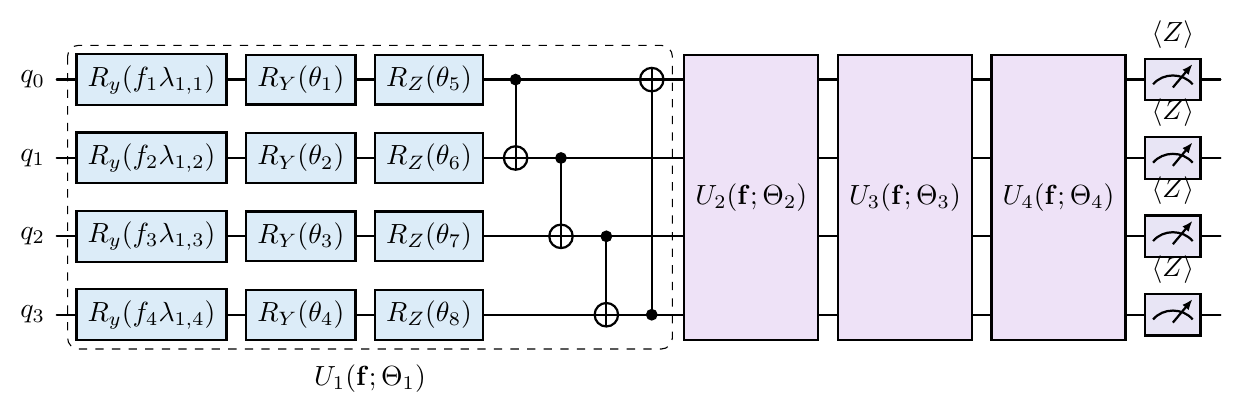

shared [[-0.20256945  0.13678573]
 [-0.38258675 -0.07745522]]


### per_action — gradient-validation model

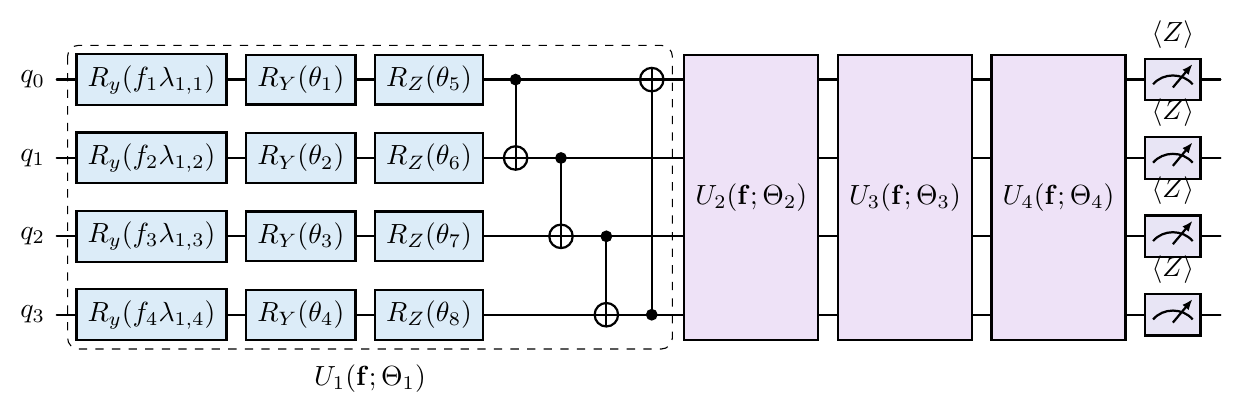

per_action [[-0.5081003   0.25744772]
 [-0.48218998  0.20040107]]


### parity_a2 — gradient-validation model

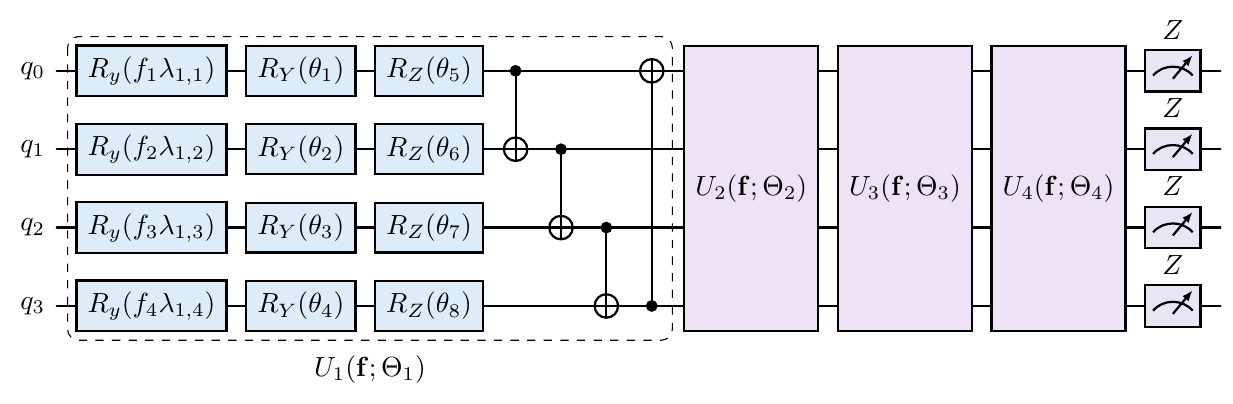

parity_a2 [[-0.70407426  0.5757336 ]
 [-0.69187754  0.55169207]]


### majority_a2 — gradient-validation model

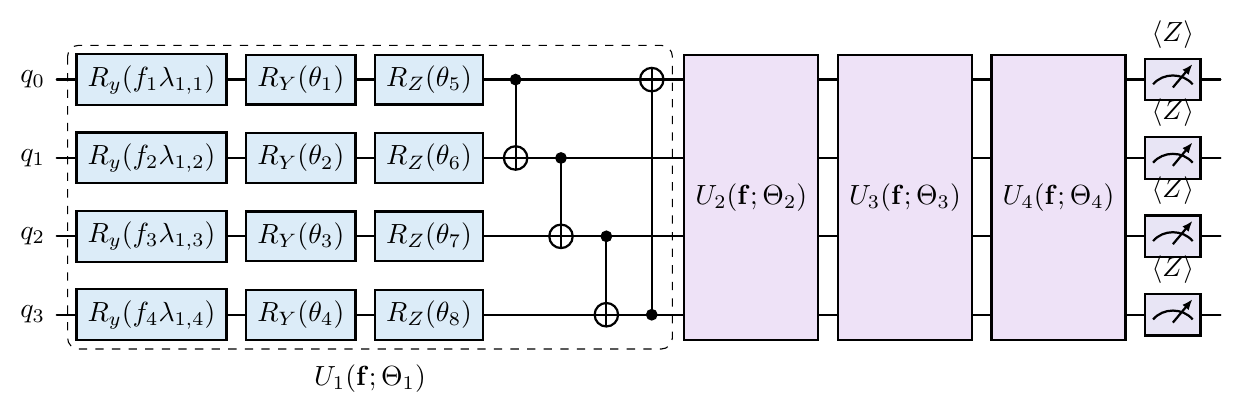

majority_a2 [[ 0.23069066 -0.11030604]
 [-0.00216474 -0.04443873]]


,readout,parameter,gradient_norm
0,shared,qlayer.input_scaling_params,0.068445
1,shared,qlayer.params,0.669033
2,shared,fc_layer.weight,0.377288
3,shared,fc_layer.bias,1.176313
4,per_action,qlayer.input_scaling_params,0.147912
5,per_action,qlayer.params,2.206627
6,per_action,fc_layer.weight,2.783759
7,parity_a2,qlayer.input_scaling_params,0.162443
8,parity_a2,qlayer.params,2.593783
9,parity_a2,fc_layer.weight,0.902896


In [3]:
models, gradient_rows = {}, []
for name, readout in READOUTS.items():
    torch.manual_seed(7)
    model = create_qfunction(dict(BASE_CONFIG, **readout), n_qubits=4, n_actions=2)
    drawing = save_circuit_drawing(model, DRAWINGS / "gradients", name)
    show_drawing(drawing, name + " — gradient-validation model")
    inputs = torch.tensor([[0.1, 0.2, -0.1, 0.3], [-0.2, 0.1, 0.2, -0.1]])
    values = model(inputs)
    assert values.shape == (2, 2) and (model.fc_layer.bias is not None) == readout["fc_bias"]
    values.square().sum().backward()
    for parameter, value in model.named_parameters():
        assert value.grad is not None and torch.isfinite(value.grad).all()
        gradient_rows.append({"readout": name, "parameter": parameter,
                              "gradient_norm": float(value.grad.norm())})
    models[name] = model
    print(name, values.detach().numpy())
display(pd.DataFrame(gradient_rows))

## Individual Pauli features and exact decomposition support

The network uses raw Pauli expectations, not fixed action probabilities.
For independent verification only, reconstruct Born decoder probabilities from
these features plus an explicit identity constant, using the old decomposition
coefficients. Reference policies use a=2 actions, whereas every PQDQN
still outputs two Q-values. All reference models are drawn too.


/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


### parity_a2 — Born reference used only for validation

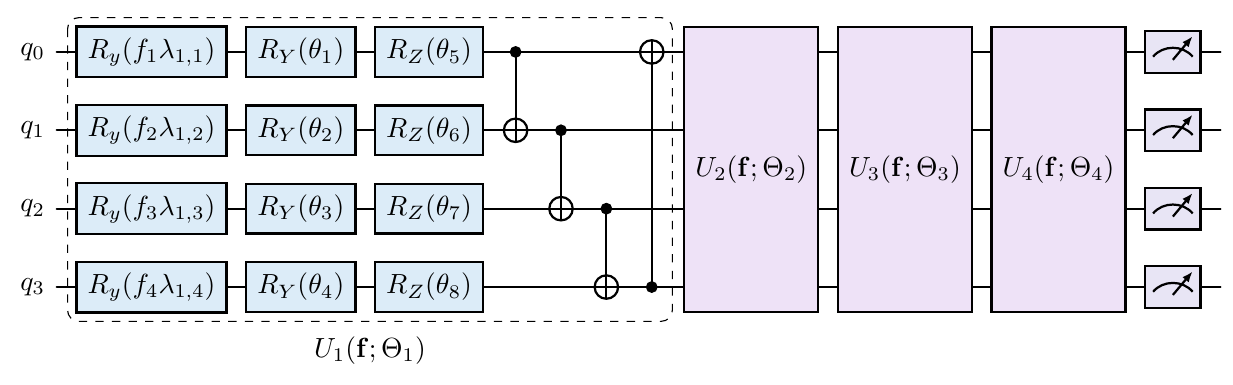

### majority_a2 — Born reference used only for validation

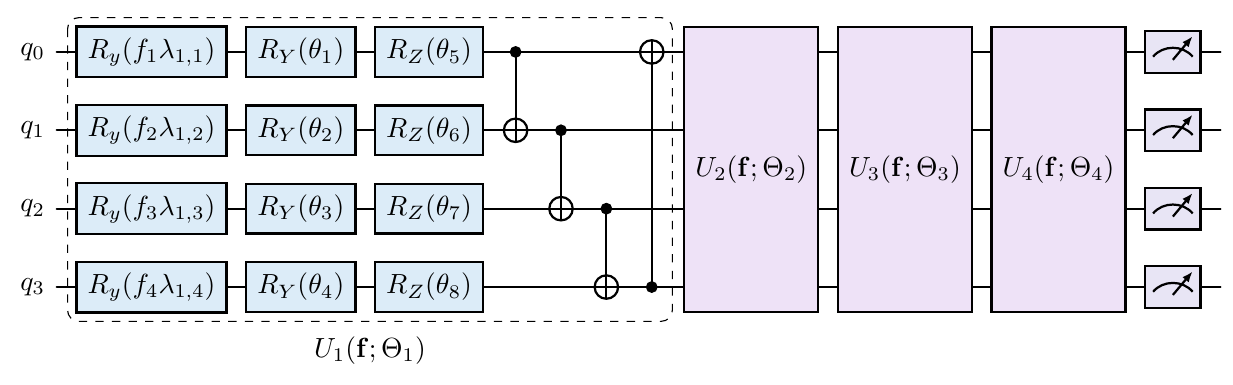

,readout,preset_actions,features,feature_count,reconstruction_error
0,parity_a2,2,[ZZZZ 0 1 2 3],1,1.192093e-07
1,majority_a2,2,"[ZZZZ 0 1 2 3, ZZZ 0 1 2, ZZZ 0 1 3, ZZZ 0 2 3...",15,5.960464e-08


In [4]:
from qasp.rl.policies import PQCBornVariance
from qasp.rl.qfunctions.observables import predefined_observables
comparison = []
for name, readout in READOUTS.items():
    if not isinstance(readout["observables"], str):
        continue
    model = models[name]
    a = readout["preset_actions"]
    policy = PQCBornVariance(
        circuit_builder=deepcopy(model.circuit_builder), n_qubits=4, n_actions=a,
        policy=readout["observables"], majority_blocks=readout.get("majority_blocks"),
        training_method="probs", device="default.qubit", diff_method="backprop",
    )
    policy.qlayer.load_state_dict(model.qlayer.state_dict())
    drawing = save_circuit_drawing(policy, DRAWINGS / "references", name + "_born")
    show_drawing(drawing, name + " — Born reference used only for validation")
    inputs = torch.tensor([0.2, -0.4, 0.1, 0.3])
    features = model.quantum_features(inputs)
    torch.testing.assert_close(features, model.qlayer(torch.tanh(inputs)).flatten())
    assert model.fc_layer.in_features == len(model.observable_strings)
    assert model.fc_layer.out_features == 2 and model.fc_layer.bias is not None
    strings, coefficients = predefined_observables(
        readout["observables"], 4, a, majority_blocks=readout.get("majority_blocks"),
        mode="projectors",
    )
    lookup = dict(zip(model.observable_strings, features))
    terms = torch.stack([features.new_tensor(1.) if s.startswith("I ") else lookup[s]
                         for s in strings])
    reconstructed = torch.as_tensor(coefficients, dtype=features.dtype) @ terms
    expected = policy(torch.tanh(inputs))
    torch.testing.assert_close(reconstructed, expected, atol=1e-6, rtol=1e-6)
    comparison.append({"readout": name, "preset_actions": a,
                       "features": list(model.observable_strings),
                       "feature_count": len(features),
                       "reconstruction_error": float((reconstructed-expected).abs().max().detach())})
assert models["parity_a2"].observable_strings == ("ZZZZ 0 1 2 3",)
display(pd.DataFrame(comparison))


## CartPole smoke runs

Eight episodes per readout with replay updates and a 100-step cap. Each freshly
created training model is drawn before training. This is not the convergence
experiment; the companion notebook uses 400 episodes and five seeds per readout.

/private/tmp/qasp-slurm-venv/lib/python3.13/site-packages/pennylane/operation.py:1982: PennyLaneDeprecationWarning: The 'id' argument is deprecated and will be removed in v0.46.
  super().__init__(*params, wires=wires, id=id)


### shared — CartPole smoke model

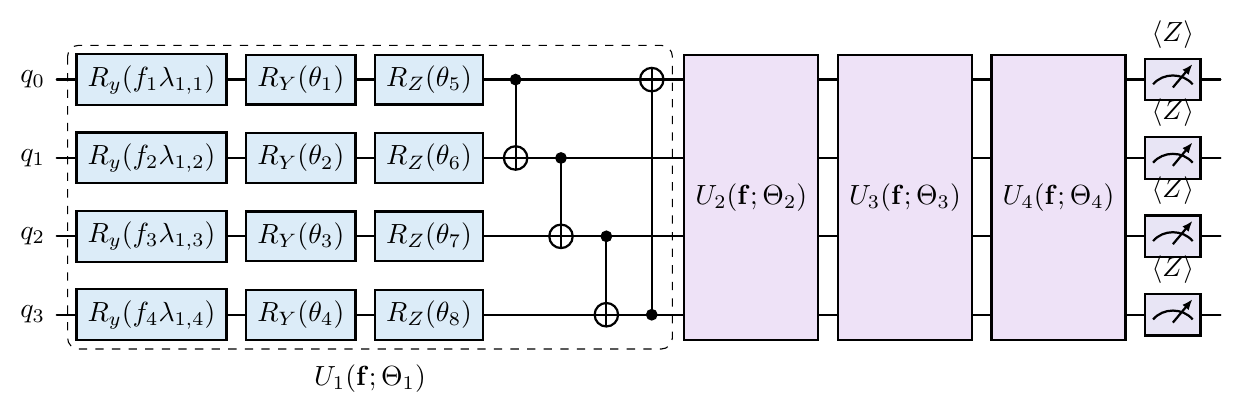

### per_action — CartPole smoke model

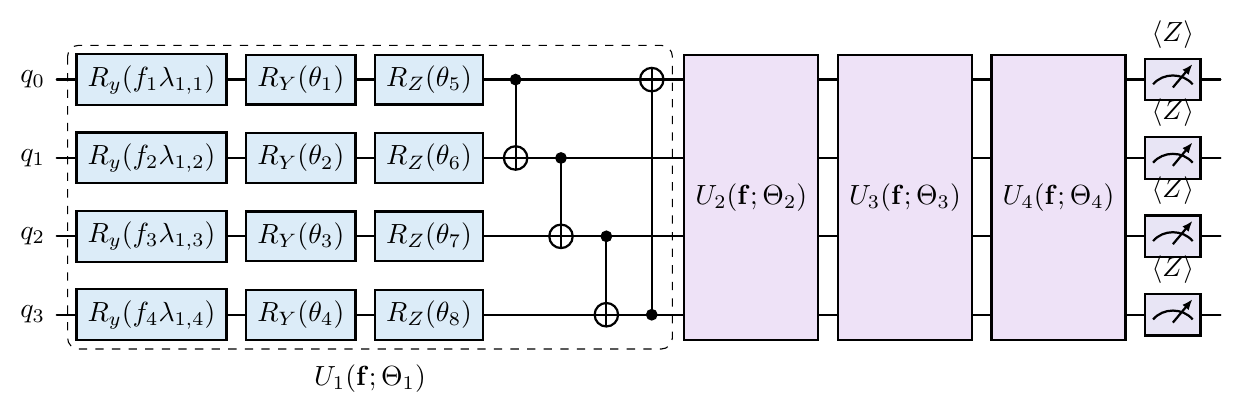

### parity_a2 — CartPole smoke model

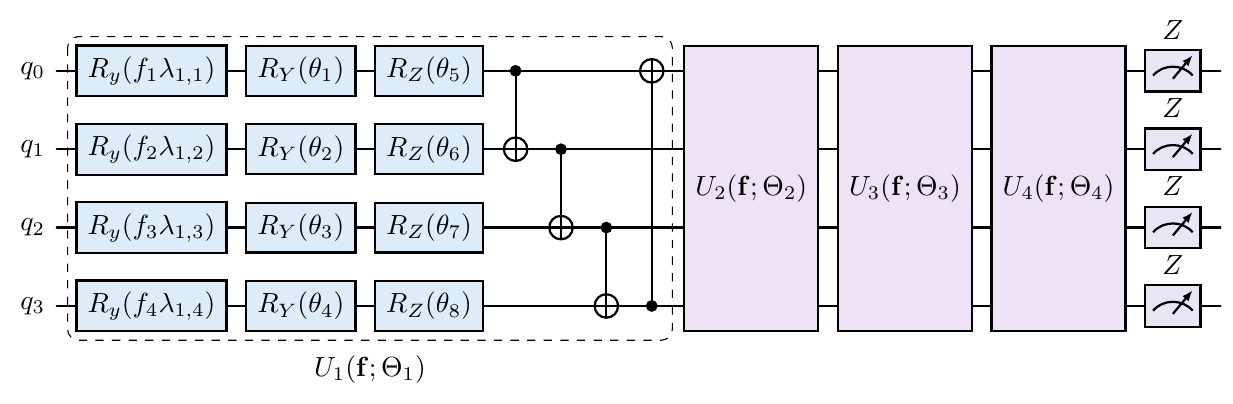

### majority_a2 — CartPole smoke model

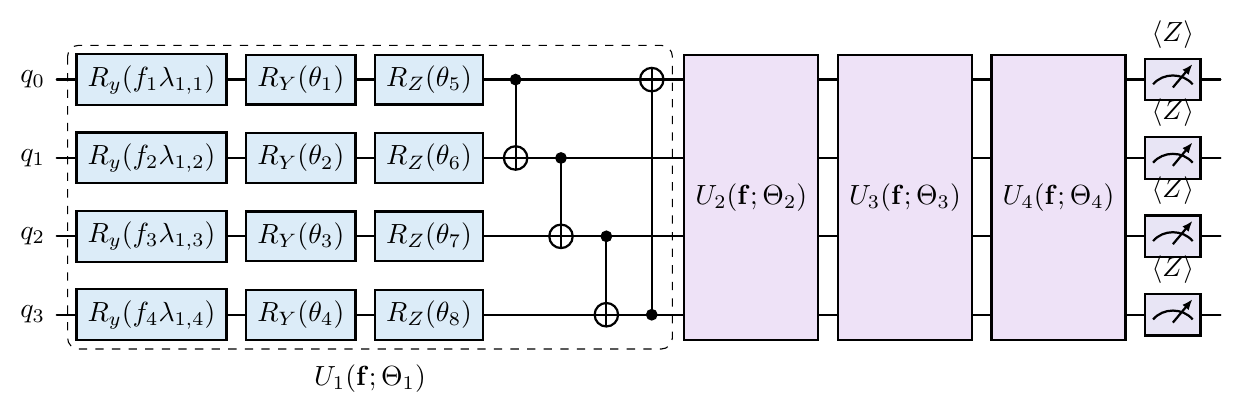

,readout,updates,circuit_parameter_change,train_return_mean,greedy_return_mean
0,shared,148,0.649330,20.375,9.2
1,per_action,148,0.537866,20.375,9.2
2,parity_a2,148,0.585781,20.375,9.2
3,majority_a2,148,0.785805,20.375,9.0


All readout integration checks passed.


In [5]:
smoke_rows = []
for name, readout in READOUTS.items():
    torch.manual_seed(11)
    model = create_qfunction(dict(BASE_CONFIG, **readout), n_qubits=4, n_actions=2)
    drawing = save_circuit_drawing(model, DRAWINGS / "smoke", name)
    show_drawing(drawing, name + " — CartPole smoke model")
    initial = model.qlayer.params.detach().clone()
    with DeepQLearning(model, "CartPole-v1", seed=11, batch_size=16,
                       learning_starts=16, max_steps=100, target_update_interval=20) as trainer:
        history = trainer.train(8, log_every=0)
        evaluation = trainer.evaluate(5, seed=20000)
        delta = float((model.qlayer.params.detach() - initial).norm())
        assert trainer.update_count > 0 and delta > 0
        assert all(np.isfinite(row["loss"]) for row in history if row["loss"] is not None)
        smoke_rows.append({"readout": name, "updates": trainer.update_count,
                           "circuit_parameter_change": delta,
                           "train_return_mean": np.mean([r["return"] for r in history]),
                           "greedy_return_mean": np.mean(evaluation)})
smoke = pd.DataFrame(smoke_rows)
display(smoke)
print("All readout integration checks passed.")

All TikZ sources, vector PDFs, and PDF-rendered previews are saved under
`examples/results/pqdqn_validation_pauli_features_bias_v2/drawings/`.

These figures use QASP's shared Quantikz exporter and the pastel style in
`drawing_quantum_circuits.ipynb`. The compact view expands the entire first
layer (encoding, Y/Z rotations, and CNOT ring) and shows layers 2–4 as unitary
blocks. The expanded source/PDF contains all gates. Each block depends on the
encoded observation **f = tanh(s)**; Θ_l includes that layer's rotation and
input-scaling parameters. The λ indices distinguish scaling between layers.
Measurement meters show local bases. The Pauli strings and fixed readout
coefficients are saved in each model's `_readout.json`; the classical linear
layer has a bias for shared and preset features. The Born reference figures show probability measurements.

Rendering requires `pdflatex` with Quantikz and `pdftoppm` (or macOS `sips`).
The vector PDF is the paper figure; the embedded PNG is its notebook preview.